In [32]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-13


# Cas de référence : échantillon monolithique

Noms des campagnes : 
- `campagne_honey`
- `campagne_honey_CC`
- `campagne_honey_UR3_S13`
- `campagne_honey_UR3_S7`

## Mapping sans CC en fct de theta et la taille du motif

Lecture des données réalisée en 1.92740s


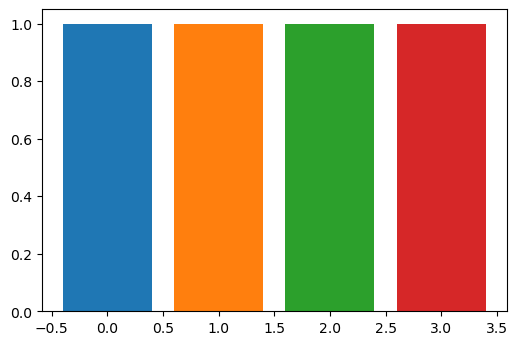

In [33]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


# C=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'forestgreen']
C= ['C0','C1','C2','C3']
colors=C
for i, co in enumerate(C):
    plt.bar([i], [1], color=co)


campagnes = ['campagne_honey','campagne_carre','campagne_trian', 'campagne_hexac']
# Can be long the first time
data=read_data_from_database(campagnes)
data_bulk = get_bulk_data(data)


[11.14889084301956, 52.60742576457445, 161.73930616551064, 144.5445614281887]


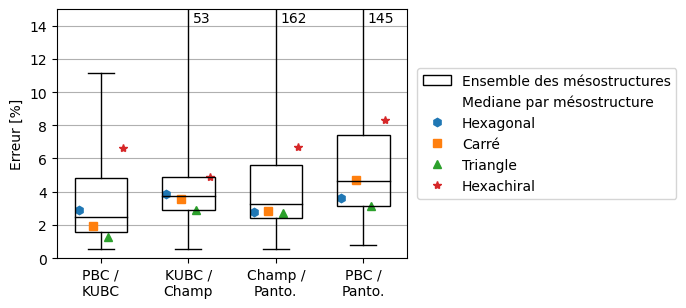

In [34]:
err = [[] for i in range(4)]


for _, test in data_bulk.items():
    err[0].append(test.get_error((0, 1)))
    err[1].append(test.get_error((1, 2)))
    err[2].append(test.get_error((2, 3)))
    err[3].append(test.get_error((0, 3)))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = test.get_error((0, 1))
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = test.get_error((1, 2))
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = test.get_error((2, 3))
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = test.get_error((0, 3))
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':''},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=C[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=C[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=C[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=C[3], marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Ensemble des mésostructures','Mediane par mésostructure','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=15, bottom=0)
plt.ylabel('Erreur [%]')
plt.xticks(range(1, 5), ['PBC /\nKUBC',
                         'KUBC /\nChamp',
                         'Champ /\nPanto.',
                         'PBC /\nPanto.'])

plt.text(2.05,14.9,f'{max(err[1][:]):.0f}', va='top', ha='left')
plt.text(3.05,14.9,f'{max(err[2][:]):.0f}', va='top', ha='left')
plt.text(4.05,14.9,f'{max(err[3][:]):.0f}', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians

for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], markers[i_geo], color=C[i_geo])
plt.grid(axis='y')

plt.subplots_adjust(top=0.98,bottom=0.15,left=0.1,right=0.6,hspace=0.2,wspace=0.25)
plt.savefig('images/mapping_error_glob.pdf')


[3.752313755096368e-10, 1.4117661717480844e-06, 25.816315566721087, 55.421979668123186]


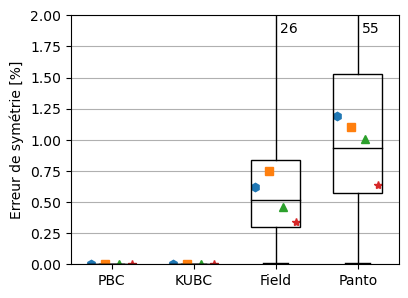

In [35]:

#~ Erreur de symétrie
err = [[] for i in range(4)]


for _, test in data_bulk.items():
    err[0].append(get_sym_error(test.K_plane_stress_PBC))
    err[1].append(get_sym_error(test.K_plane_stress_KUBC))
    err[2].append(get_sym_error(test.K_field_dic))
    err[3].append(get_sym_error(test.K_panto_dic))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = get_sym_error(test.K_plane_stress_PBC)
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = get_sym_error(test.K_plane_stress_KUBC)
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = get_sym_error(test.K_field_dic)
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = get_sym_error(test.K_panto_dic)
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(4, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':''},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=C[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=C[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=C[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=C[3], marker='*', linestyle='')
# plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Ensemble des mésostructures','Mediane par mésostructure','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
#            fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=2, bottom=0)
plt.ylabel('Erreur de symétrie [%]')
plt.xticks(range(1, 5), ['PBC',
                         'KUBC',
                         'Field',
                         'Panto'])


plt.text(3.05,1.95,f'{max(err[2][:]):.0f}', va='top', ha='left')
plt.text(4.05,1.95,f'{max(err[3][:]):.0f}', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians

for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], markers[i_geo], color=C[i_geo])
plt.grid(axis='y')

plt.subplots_adjust(top=0.98,bottom=0.15,left=0.16,right=0.98,hspace=0.2,wspace=0.25)
plt.savefig('images/mapping_error_sym.pdf')


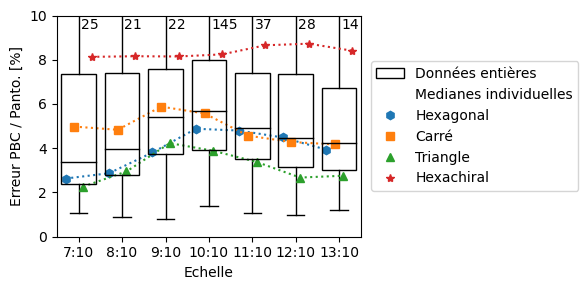

In [36]:

err = [[] for i in range(7)]

for test_id, test in data_bulk.items():
    err[int(test_id.split('_')[1])-7].append(test.get_error((0, 3)))

mean_err_per_geo = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_error((0, 3))
        counter[scale,geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(6, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':''},widths=0.8)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color=C[0], marker='h', linestyle='')
carre = mlines.Line2D([], [], color=C[1], marker='s', linestyle='')
trian = mlines.Line2D([], [], color=C[2], marker='^', linestyle='')
hc = mlines.Line2D([], [], color=C[3], marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


ymax=10

markers = ['h:', 's:', '^:', '*:']
n=5 # Space between indivuals medians

for i_geo in range(4):
    plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=C[i_geo])

for i in range(7):
    plt.text(i+1.05,ymax-0.1,f'{max(err[i][:]):.0f}', va='top', ha='left')


plt.ylim(bottom=0.0,top=ymax)

plt.xlabel('Echelle')
plt.ylabel('Erreur PBC / Panto. [%]')
plt.xticks(range(1, 8), ['7:10','8:10','9:10','10:10','11:10','12:10','13:10'])

plt.tight_layout()
plt.savefig('images/error_per_scale.pdf')

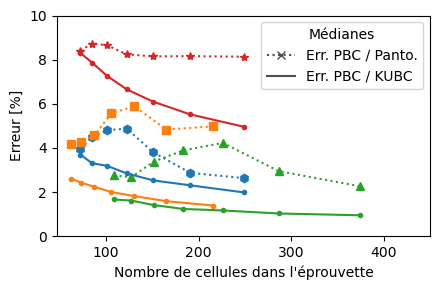

In [37]:

mean_err_per_geo_th = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo_th[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo_th[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_error((0, 1))
        counter[scale,geo_idx] += 1

mean_err_per_geo_th = np.nanquantile(mean_err_per_geo_th,0.5, axis=2).tolist()
nb_cell=[]
L0=28

for scale in range(7,14):
    L=L0*scale/10
    nb_cell.append([288**2/(L/2*L*tan(pi/6)+L*L*tan(pi/6)),         # Hexa
                         288**2/(L**2),                             # Carre
                         288**2/(L*L*tan(pi/6))])                   # Triangle


markers = ['h:', 's:', '^:', '*:']
plt.figure(figsize=(4.5,3))
n=5 # Space between indivuals medians
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=C[i_geo])

markers = ['.-']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_th], markers[i_geo], color=C[i_geo])


# * Legende
l0 =  mlines.Line2D([], [], color='0.3', marker='x', linestyle=':')
l1 = mlines.Line2D([], [], color='0.3', marker='', linestyle='-')
plt.legend([l0,l1,],['Err. PBC / Panto.','Err. PBC / KUBC'],
           fancybox=True, title='Médianes')


plt.xlabel('Nombre de cellules dans l\'éprouvette')
plt.ylabel('Erreur [%]')
plt.ylim((0,10))
plt.xlim(right=450)
plt.tight_layout()
plt.savefig('images/error_per_nb_cells.pdf')




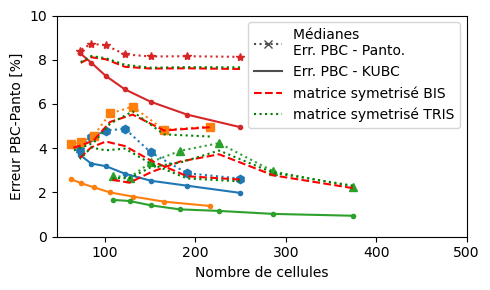

In [38]:

def get_sym_part(k:list)-> np.ndarray:
    k=np.array(k)
    k_sym = 0.5*(k+np.transpose(k))
    return k_sym

def get_sym_part2(k:list)-> np.ndarray:
    k=np.array(k)
    k[1,0]=k[0,1]
    k[2,0]=k[0,2]
    k[2,1]=k[1,2]
    # k[0,1]=k[1,0]
    # k[0,2]=k[2,0]
    # k[1,2]=k[2,1]
    return k

# ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~
mean_err_per_geo_bis = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo_bis[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        err_custom = get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic))
        mean_err_per_geo_bis[scale, geo_idx, int(counter[scale,geo_idx])] = err_custom
        counter[scale,geo_idx] += 1

mean_err_per_geo_bis = np.nanquantile(mean_err_per_geo_bis,0.5, axis=2).tolist()

mean_err_per_geo_tris = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo_tris[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        err_custom = get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part2(test.K_panto_dic))
        mean_err_per_geo_tris[scale, geo_idx, int(counter[scale,geo_idx])] = err_custom
        counter[scale,geo_idx] += 1

mean_err_per_geo_tris = np.nanquantile(mean_err_per_geo_tris,0.5, axis=2).tolist()

# - - - - - - - - - -
nb_cell=[]
L0=28

for scale in range(7,14):
    L=L0*scale/10
    nb_cell.append([288**2/(L/2*L*tan(pi/6)+L*L*tan(pi/6)),         # Hexa
                         288**2/(L**2),                             # Carre
                         288**2/(L*L*tan(pi/6))])                   # Triangle


markers = ['h:', 's:', '^:', '*:']
plt.figure(figsize=(5,3))
n=5 # Space between indivuals medians
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo], markers[i_geo], color=C[i_geo])

markers = ['.-']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_th], markers[i_geo], color=C[i_geo])

markers = ['--']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_bis], markers[i_geo], color='red')


markers = [':']*4
for i_geo in range(4):
    plt.plot([nb_cell[i_error][i_geo%3] for i_error in range(7)], [e[i_geo] for e in mean_err_per_geo_tris], markers[i_geo], color='green')


# * Legende
l0 =  mlines.Line2D([], [], color='0.3', marker='x', linestyle=':')
l1 = mlines.Line2D([], [], color='0.3', marker='', linestyle='-')
l2 = mlines.Line2D([], [], color='red', marker='', linestyle='--')
l3 = mlines.Line2D([], [], color='g', marker='', linestyle=':')
plt.legend([l0,l1,l2,l3],['Médianes \nErr. PBC - Panto.','Err. PBC - KUBC', 'matrice symetrisé BIS','matrice symetrisé TRIS'],
           fancybox=True)


plt.xlabel('Nombre de cellules')
plt.ylabel('Erreur PBC-Panto [%]')
plt.ylim((0,10))
plt.xlim(right=500)
plt.tight_layout()
# plt.savefig('images/error_per_nb_cells.pdf')
plt.show()


Lecture des données réalisée en 0.11211s
0
honeyCC_7_0_4_4
honeyCC_7_12_2_6
honeyCC_7_1_2_6
honeyCC_7_5_2_6
1
carreCC_7_9_5_5
2
triaCC_7_10_5_2
triaCC_7_11_0_1
triaCC_7_12_0_5 non trouvé
triaCC_7_12_1_1
triaCC_7_12_2_3 non trouvé
triaCC_7_12_3_4 non trouvé
triaCC_7_12_4_3 non trouvé
triaCC_7_12_6_1 non trouvé
triaCC_7_12_6_3 non trouvé
triaCC_7_12_6_4
3


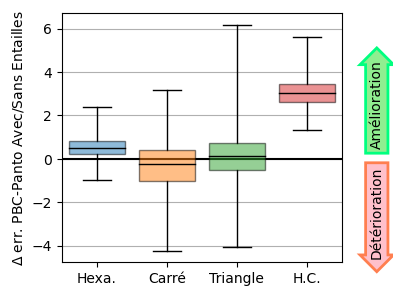

In [39]:

campagnes_CC = ['campagne_honey_CC','campagne_carre_CC','campagne_trian_CC', 'campagne_hexac_CC']
# Can be long the first time
data_CC=read_data_from_database(campagnes_CC)
data_CC_bulk = get_bulk_data(data_CC)


amelioration=[[] for i in range(4)]
eoi=(0,3)

for c_name, campagne in data_CC.items():
    geo_idx = campagnes_CC.index(c_name)
    print(geo_idx)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('CC','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_error(eoi)-ref.get_error(eoi)))

        if abs(-(test.get_error(eoi)-ref.get_error(eoi))-1)<0.01:
            print(test_id)


plt.figure(figsize=(4, 3))
plt.axhline(0, color='black')
for i_geo in range(4):
    plt.boxplot([amelioration[i_geo]], patch_artist=True, whis=(0, 100), medianprops={
                'color': 'k'},boxprops={'facecolor':C[i_geo],'alpha':0.5},widths=0.8,positions=[i_geo+1])

# plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
#                 'color': 'k'},widths=0.8)

plt.text(5, 2.5, "Amélioration",
            ha="center", va="center", rotation=90, size=10,
            bbox=dict(boxstyle="rarrow,pad=0.3",
                      fc="lightgreen", ec="springgreen", lw=2))

plt.text(5, -2.5, "Détérioration",
            ha="center", va="center", rotation=90, size=10,
            bbox=dict(boxstyle="larrow,pad=0.3",
                      fc="pink", ec="coral", lw=2))
plt.grid(axis='y')

plt.xticks(range(1,5),['Hexa.', 'Carré', 'Triangle', 'H.C.'])
plt.ylabel(r'$\Delta$ err. PBC-Panto Avec/Sans Entailles')


plt.subplots_adjust(top=0.98,bottom=0.15,left=0.15,right=0.85,hspace=0.2,wspace=0.25)
plt.savefig('images/effet_cc_err.pdf')

Lecture des données réalisée en 0.21541s
triaUR3_7_12_0_5 non trouvé
triaUR3_7_12_2_3 non trouvé
triaUR3_7_12_3_4 non trouvé
triaUR3_7_12_4_3 non trouvé
triaUR3_7_12_6_1 non trouvé
triaUR3_7_12_6_3 non trouvé


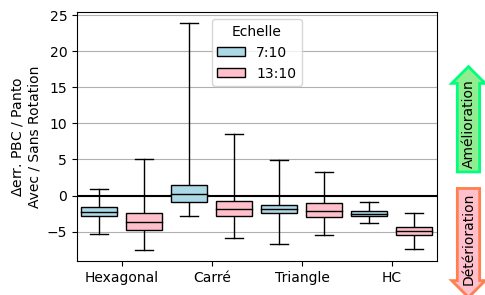

In [40]:

campagnes_R3 = ['campagne_honey_UR3',
                'campagne_carre_UR3',
                'campagne_trian_UR3', 
                'campagne_hexac_UR3']
# Can be long the first time
data_R3=read_data_from_database(campagnes_R3)



amelioration=[[] for i in range(8)]
eoi=(0,3)

for c_name, campagne in data_R3.items():
    geo_idx = campagnes_R3.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('UR3','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        s13 = 1 if test.test_id.split('_')[1]=='13' else 0
        amelioration[2*geo_idx+s13].append(-(test.get_error(eoi)-ref.get_error(eoi)))


plt.figure(figsize=(5, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': True},widths=0.8)

i=0
for bplot in bp['boxes']:
    i+=1
    if i%2==0:
        bplot.set_facecolor('pink')
    else:
        bplot.set_facecolor('lightblue')


plt.legend([bp['boxes'][0],bp['boxes'][1]],['7:10','13:10'], title='Echelle',
           fancybox=True,loc='upper center',)
plt.grid(axis='y')
plt.text(9.2, 10, "Amélioration",
            ha="center", va="center", rotation=90, size=10,
            bbox=dict(boxstyle="rarrow,pad=0.3",
                      fc="lightgreen", ec="springgreen", lw=2))

plt.text(9.2, -6, "Détérioration",
            ha="center", va="center", rotation=90, size=10,
            bbox=dict(boxstyle="larrow,pad=0.3",
                      fc="pink", ec="coral", lw=2))

plt.xticks([1.5,3.5,5.5,7.5],['Hexagonal', 'Carré', 'Triangle', 'HC'])
plt.ylabel(r"$\Delta$"+f'err. PBC / Panto\nAvec / Sans Rotation')
plt.axhline(0, color='black')

plt.subplots_adjust(top=0.98,bottom=0.15,left=0.15,right=0.87,hspace=0.2,wspace=0.25)
plt.savefig('images/UR3_effect.pdf')

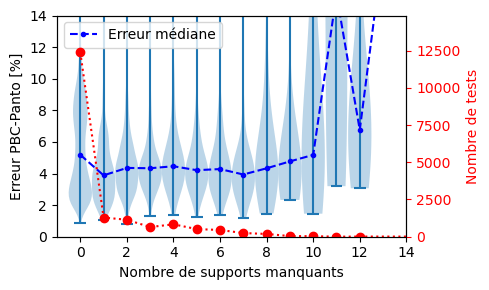

In [41]:

def err_per_number_of_ms(data: dict[Test], eoi:tuple=(0,3), step:float=0.9, width:float=0.1) -> None:
    x_scatter, y_scatter = [], []
    for _, test in data.items():
        err = test.get_error(eoi)
        number_missing_support = sum([len(i) for i in test.skipped_cyl])
        x_scatter.append(number_missing_support)
        y_scatter.append(err)

    X_sorted, Y_sorted = (list(t) for t in zip(*sorted(zip(x_scatter, y_scatter))))
    old = X_sorted[0]
    X_bulk, Y_bulk, number_per_x= [old], [[]], []
    counter=0
    for x, y in zip(X_sorted, Y_sorted):
        if x<old+step:
            Y_bulk[-1].append(y)
            counter+=1
            continue
        number_per_x.append(counter)
        X_bulk.append(x)
        Y_bulk.append([y])
        old = x
        counter=0
    number_per_x.append(counter)
    y_mean = []
    for y in Y_bulk:
        y_mean.append(np.quantile(np.array(y),0.5))
    y_mean = np.array(y_mean)

    plt.violinplot(Y_bulk, X_bulk,widths=width,
                   showmeans=False, showmedians=False, showextrema=True)
    plt.plot(X_bulk, y_mean, '.b--', label='Erreur médiane')
    plt.xlabel(f'Nombre de supports manquants')
    plt.ylim((-0,14))
    plt.xlim((-1,14))
    plt.ylabel('Erreur PBC-Panto [%]')
    plt.legend()
    ax2=plt.twinx()
    ax2.set_ylim(bottom=0, top=1.2*np.max(number_per_x))
    ax2.plot(X_bulk, number_per_x, 'ro:')
    ax2.set_ylabel('Nombre de tests', color='r')
    ax2.tick_params(axis='y', colors='red')


# to_plot=['data', 'data_scale_7','data_scale_8', 'data_scale_9', 'data_scale_10', 
#          'data_scale_11', 'data_scale_12', 'data_scale_13']
to_plot=['data']

plt.figure(figsize=(5,3))
err_per_number_of_ms(data_bulk, width=1.0)
plt.tight_layout()
plt.savefig('images/MS_full.pdf')

Lecture des données réalisée en 0.75903s
C0


<ipython-input-42-86198bbeea43>:51: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  plt.ylim(bottom=0.0)


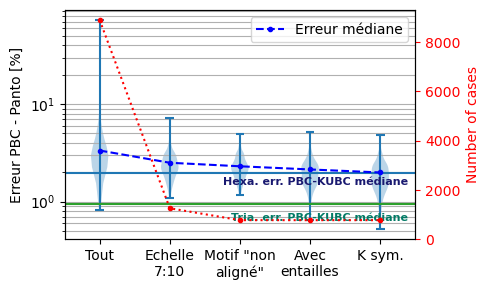

In [42]:
data_raw = get_bulk_data(read_data_from_database(['campagne_honey','campagne_trian']))

data_list = [[], [], [], [], []]
last_tests_dict={}
eoi = (0, 3)
for test_id, test in data_raw.items():
    # * list of conditions
    stage = 0
    data_list[stage].append(test.get_error(eoi))

    if test.test_id.split('_')[1] not in ['7']:  # * Si l'angle est de 0 ou 15°
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    

    if test.test_id.split('_')[2] in ['0','1','6','11','12']:
        continue
    stage += 1
    data_list[stage].append(test.get_error(eoi))

    t_cc_name=test_id.split('_')
    t_cc_name[0]+='CC'
    t_cc=data_CC_bulk['_'.join(t_cc_name)]
    stage += 1
    data_list[stage].append(t_cc.get_error(eoi))

    stage += 1
    data_list[stage].append(get_error_custom(np.array(t_cc.K_plane_stress_PBC),get_sym_part(t_cc.K_panto_dic)))
    last_tests_dict |= {'_'.join(t_cc_name):t_cc}


plt.figure(figsize=(5,3))
plt.yscale('log')
plt.violinplot(data_list, range(len(data_list)), widths=0.25,
               showmeans=False, showmedians=False, showextrema=True)


plt.plot(range(len(data_list)), [np.quantile(np.array(i),0.5) for i in data_list], 'b.--', label='Erreur médiane')
plt.hlines(mean_err_per_geo_th[0][0], -10,10,colors=colors[0], linestyles='-')
plt.hlines(mean_err_per_geo_th[0][2], -10,10,colors=colors[2], linestyles='-')

plt.text(4.4,1.6,'Hexa. err. PBC-KUBC médiane',va="center", ha="right", color='midnightblue',size=8,fontweight='bold')
plt.text(4.4,0.6,'Tria. err. PBC-KUBC médiane',va="bottom", ha="right", color='#027a65',size=8,fontweight='bold')

print(colors[0])


plt.xticks(range(len(data_list)), ['Tout', 'Echelle\n7:10', 'Motif "non\naligné"', 'Avec\nentailles', 'K sym.'])
plt.ylim(bottom=0.0)
plt.ylabel('Erreur PBC - Panto [%]')


plt.grid(axis='y', which="both", ls="-")
plt.legend()
plt.xlim((-0.5,4.5))
plt.twinx()
plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
plt.ylabel('Number of cases', color='r')
plt.tick_params(axis='y', colors='red')
plt.ylim(bottom=0.0)

plt.tight_layout()
plt.savefig('images/MS_full_selection.pdf')
plt.show()

- - - - - - - - - - - - - - - - - - - - 

campagne_honey
Lecture des données réalisée en 0.19695s
[3.644950689385384, 2.6295648348063847, 2.5533392881582317, 2.090495685615845, 1.9846563661904995]


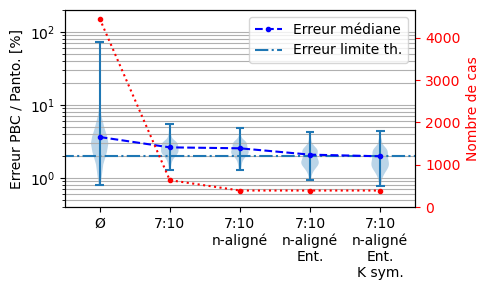

- - - - - - - - - - - - - - - - - - - - 

campagne_carre
Lecture des données réalisée en 0.60977s
[4.682513081255776, 4.978110422657913, 5.404825865802635, 5.6708831383825595, 5.782518939466972]


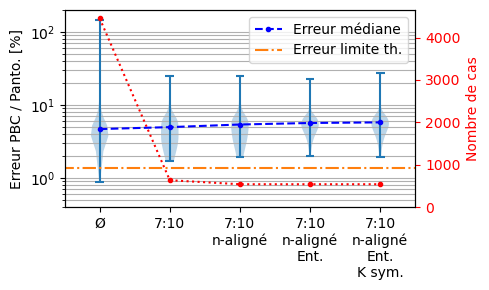

- - - - - - - - - - - - - - - - - - - - 

campagne_trian
Lecture des données réalisée en 0.17059s
[3.130862507900095, 2.2645504958367373, 2.128773831976443, 2.1487480487055093, 2.03140222415785]


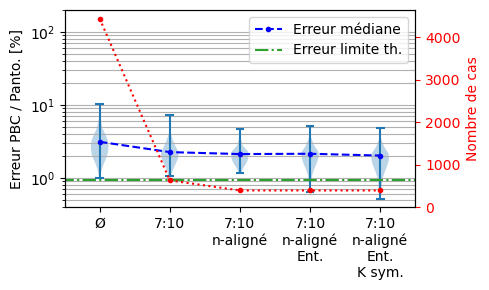

- - - - - - - - - - - - - - - - - - - - 

campagne_hexac
Lecture des données réalisée en 0.65005s
[8.31607756545369, 8.130799587903569, 8.099302596826348, 5.052849727302166, 4.850327009593993]


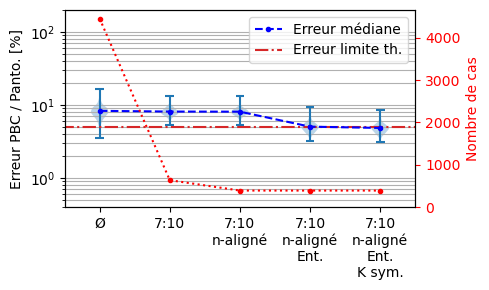

In [43]:
for i_meso,mesostructure in enumerate(['campagne_honey','campagne_carre','campagne_trian','campagne_hexac']):
    print('- '*20+'\n')
    print(mesostructure)
    data_raw = get_bulk_data(read_data_from_database([mesostructure]))

    data_list = [[], [], [], [], []]
    if mesostructure == 'campagne_honey':
        last_tests_dict={}
    eoi = (0, 3)
    for test_id, test in data_raw.items():
        # * list of conditions
        stage = 0
        data_list[stage].append(test.get_error(eoi))

        if test.test_id.split('_')[1] not in ['7']:  
            continue
        stage += 1
        data_list[stage].append(test.get_error(eoi))

        
        if test.test_id.split('_')[0]=='carre':
            if test.test_id.split('_')[2] in ['0','1','15','16']:
                continue
        else:
            if test.test_id.split('_')[2] in ['0','1','6','11','12']:
                continue
        stage += 1
        data_list[stage].append(test.get_error(eoi))

        t_cc_name=test_id.split('_')
        t_cc_name[0]+='CC'
        t_cc=data_CC_bulk['_'.join(t_cc_name)]
        stage += 1
        data_list[stage].append(t_cc.get_error(eoi))

        stage += 1
        data_list[stage].append(get_error_custom(np.array(t_cc.K_plane_stress_PBC),get_sym_part(t_cc.K_panto_dic)))
        if mesostructure == 'campagne_honey':
            last_tests_dict |= {'_'.join(t_cc_name):t_cc}


    plt.figure(figsize=(5,3))
    plt.yscale('log')
    vc=plt.violinplot(data_list, range(len(data_list)), widths=0.25,
                showmeans=False, showmedians=False, showextrema=True, 
    )

    # for pc in vc['bodies']:
    #     pc.set_facecolor(C[i_meso])


    plt.plot(range(len(data_list)), [np.quantile(np.array(i),0.5) for i in data_list], '.--', color='b', label='Erreur médiane')
    plt.hlines(mean_err_per_geo_th[0][i_meso], -10,10,colors=C[i_meso], linestyles='-.', label='Erreur limite th.')

    print([np.quantile(np.array(i),0.5) for i in data_list])


    plt.xticks(range(len(data_list)), ['Ø', '7:10', '7:10\nn-aligné', '7:10\nn-aligné\nEnt.', '7:10\nn-aligné\nEnt.\nK sym.'])
    plt.ylim(bottom=0.4, top=200)
    plt.ylabel('Erreur PBC / Panto. [%]')


    plt.grid(axis='y', which="both", ls="-")
    plt.legend()
    plt.xlim((-0.5,4.5))
    plt.twinx()
    plt.plot(range(len(data_list)), [len(i) for i in data_list], 'r.:')
    plt.ylabel('Nombre de cas', color='r')
    plt.ylim(bottom=0)
    plt.tick_params(axis='y', colors='red')


    plt.tight_layout()
    plt.savefig(f'images/MS_full_selection_{mesostructure}.pdf')
    plt.show()

nb_tirage=391
Lecture des données réalisée en 0.17706s


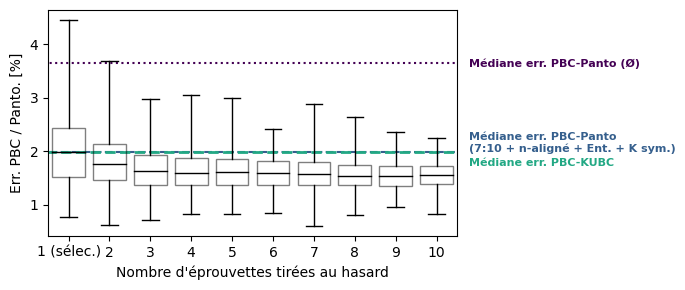

In [44]:
from random import randint

data_set={}
err_PBC_Panto=[]
err_PBC_KUBC=[]
for test_id, test in last_tests_dict.items():
    if 'honey' in test_id:
        data_set|={test_id: test}
        err_PBC_Panto.append(get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic)))
        err_PBC_KUBC.append(test.get_error((0,1)))

err_list=[]
nb_par_tirage=range(1,11)
nb_tirage = len(list(data_set.keys()))
print(f'{nb_tirage=}')

for group in nb_par_tirage:
    err_list.append([])
    if group==1: # Cas particulier ou on tire qu'une éprouvette
        for test_id, test in data_set.items():
            err_list[-1].append(get_error_custom(np.array(test.K_plane_stress_PBC), get_sym_part(test.K_panto_dic)))
    else:
        for tirage in range(nb_tirage):
            k_sum=np.zeros((3,3))
            for i in range(group):
                a=randint(0,len(list(data_set.keys()))-1)
                key=list(data_set.keys())[a]
                k_sum += get_sym_part(data_set[key].K_panto_dic)
            k_mean=k_sum/group
            err_list[-1].append(get_error_custom(np.array(data_set[key].K_plane_stress_PBC), k_mean))

# - - - -
data_honey=get_bulk_data(read_data_from_database(['campagne_honey']))
err_PBC_Panto_full_data=[]
for test_id, test in data_honey.items():
    err_PBC_Panto_full_data.append(test.get_error((0,3)))


# - - - -

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err_list, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'facecolor':'none', 'alpha':0.5},widths=0.8)

plt.xticks(range(1,len(nb_par_tirage)+1),['1 (sélec.)']+[str(i) for i in nb_par_tirage if i!=1])
plt.xlim((0.5,10.5))

# yles=':',label='Médiane err. PBC-Panto (tout)')
# ',label='Médiane err. PBC-Panto (sélection)')
# label='Médiane err. PBC-KUBC')
C_ERR=list(plt.cm.viridis([0.0, 0.3 , 0.6 ]))

plt.hlines(np.quantile(np.array(err_PBC_Panto_full_data),0.5), -10,20,colors=C_ERR[0], linestyles=':')
plt.hlines(np.quantile(np.array(err_PBC_Panto),0.5), -10,20,colors=C_ERR[1], linestyles='--')
plt.hlines(np.quantile(np.array(err_PBC_KUBC),0.5), -10,20,colors=C_ERR[2], linestyles='--', lw=2)

plt.text(10.8,np.quantile(np.array(err_PBC_Panto_full_data),0.5),'Médiane err. PBC-Panto (Ø)',va="center", ha="left", color=C_ERR[0],size=8,fontweight='bold')
plt.text(10.8,np.quantile(np.array(err_PBC_Panto),0.5)+0.17,'Médiane err. PBC-Panto\n(7:10 + n-aligné + Ent. + K sym.)',va="center", ha="left", color=C_ERR[1],size=8,fontweight='bold')
plt.text(10.8,np.quantile(np.array(err_PBC_KUBC),0.5)-0.2,'Médiane err. PBC-KUBC',va="center", ha="left", color=C_ERR[2],size=8,fontweight='bold')

plt.xlabel('Nombre d\'éprouvettes tirées au hasard')
plt.ylabel('Err. PBC / Panto. [%]')
plt.ylim(bottom=0)# plt.legend()
plt.tight_layout()
plt.savefig('images/nb_eprouvette.pdf')

nb_tirage=391
Lecture des données réalisée en 0.69273s


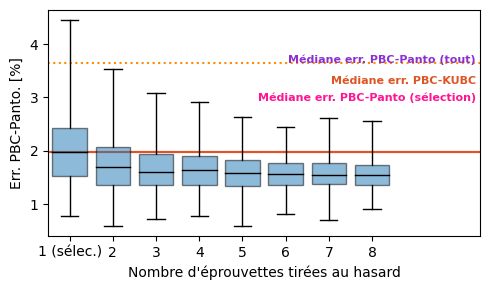

In [45]:
from random import randint

data_set={}
err_PBC_Panto=[]
err_PBC_KUBC=[]
for test_id, test in last_tests_dict.items():
    if 'honey' in test_id:
        data_set|={test_id: test}
        err_PBC_Panto.append(get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic)))
        err_PBC_KUBC.append(test.get_error((0,1)))

err_list=[]
nb_par_tirage=range(1,9)
nb_tirage = len(list(data_set.keys()))
print(f'{nb_tirage=}')

for group in nb_par_tirage:
    err_list.append([])
    if group==1: # Cas particulier ou on tire qu'une éprouvette
        for test_id, test in data_set.items():
            err_list[-1].append(get_error_custom(np.array(test.K_plane_stress_PBC), get_sym_part(test.K_panto_dic)))
    else:
        for tirage in range(nb_tirage):
            k_sum=np.zeros((3,3))
            angles_picked=[]
            for i in range(group):
                flag=False
                while flag == False:
                    a=randint(0,len(list(data_set.keys()))-1)
                    key=list(data_set.keys())[a]
                    if key.split('_')[2] not in angles_picked:
                        angles_picked.append(key.split('_')[2])
                        flag=True

                k_sum += get_sym_part(data_set[key].K_panto_dic)
            k_mean=k_sum/group
            err_list[-1].append(get_error_custom(np.array(data_set[key].K_plane_stress_PBC), k_mean))

# - - - -
data_honey=get_bulk_data(read_data_from_database(['campagne_honey']))
err_PBC_Panto_full_data=[]
for test_id, test in data_honey.items():
    err_PBC_Panto_full_data.append(test.get_error((0,3)))


# - - - -

plt.figure(figsize=(5, 3))
bp=plt.boxplot(err_list, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'facecolor':colors[0], 'alpha':0.5},widths=0.8)

plt.xticks(range(1,len(nb_par_tirage)+1),['1 (sélec.)']+[str(i) for i in nb_par_tirage if i!=1])
plt.xlim((0.5,10.5))

# yles=':',label='Médiane err. PBC-Panto (tout)')
# ',label='Médiane err. PBC-Panto (sélection)')
# label='Médiane err. PBC-KUBC')
C_ERR=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'forestgreen']

plt.hlines(np.quantile(np.array(err_PBC_Panto_full_data),0.5), -10,20,colors=C_ERR[3], linestyles=':')
plt.hlines(np.quantile(np.array(err_PBC_Panto),0.5), -10,20,colors='deeppink', linestyles='-')
plt.hlines(np.quantile(np.array(err_PBC_KUBC),0.5), -10,20,colors='#de5523', linestyles='-')

plt.text(10.4,3.7,'Médiane err. PBC-Panto (tout)',va="center", ha="right", color='#8b30d1',size=8,fontweight='bold')
plt.text(10.4,3.3,'Médiane err. PBC-KUBC',va="center", ha="right", color='#de5523',size=8,fontweight='bold')
plt.text(10.4,3.0,'Médiane err. PBC-Panto (sélection)',va="center", ha="right", color='deeppink',size=8,fontweight='bold')

plt.xlabel('Nombre d\'éprouvettes tirées au hasard')
plt.ylabel('Err. PBC-Panto. [%]')
# plt.legend()
plt.tight_layout()
# plt.savefig('images/nb_eprouvette.pdf')

Lecture des données réalisée en 0.13976s


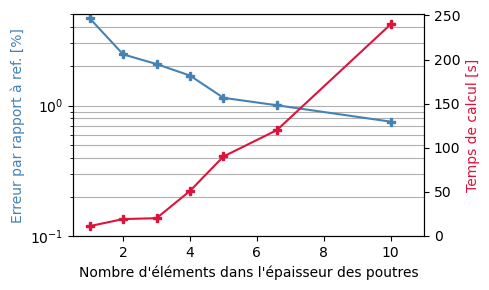

In [46]:

from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 
from matplotlib import cm

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

C=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'forestgreen']
# C=list(plt.cm.tab10([0.0, 0.1 ,0.2 ,0.3, 0.4 ]))
campagnes = ['campagne_test']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))


k1=np.array(data['Z_test_honey_11'].K_field_dic)
k2=np.array(data['Z_test_honey_22'].K_field_dic)
k3=np.array(data['Z_test_honey_33'].K_field_dic)
k4=np.array(data['Z_test_honey_44'].K_field_dic)
k5=np.array(data['Z_test_honey_5'].K_field_dic)
k6=np.array(data['Z_test_honey_6'].K_field_dic)
k7=np.array(data['Z_test_honey_7'].K_field_dic)
k8=np.array(data['Z_test_honey_8'].K_field_dic)


er=[get_error_custom(k8,k1),
get_error_custom(k8,k2),
get_error_custom(k8,k3),
get_error_custom(k8,k4),
get_error_custom(k8,k5),
get_error_custom(k8,k6),
get_error_custom(k8,k7)]

plt.figure(figsize=(5,3))
plt.plot([1,2,3,4,5,6.6,10], er, 'P-', color='steelblue')
plt.ylabel('Erreur par rapport à ref. [%]', color='steelblue')
plt.xlabel("Nombre d'éléments dans l'épaisseur des poutres")
plt.ylim((0.1,5))
plt.xlim((0.5,11))
plt.yscale('log')
plt.grid(axis='y', which="both", ls="-")
plt.twinx()
plt.plot([1,2,3,4,5,6.6,10], [11,19, 20,51,90, 120, 240],'P-', color='crimson')
plt.ylabel('Temps de calcul [s]', color='crimson')
plt.tight_layout()
plt.savefig('images/convergence.pdf')

In [50]:

from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 
from matplotlib import cm

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

C=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'forestgreen']
# C=list(plt.cm.tab10([0.0, 0.1 ,0.2 ,0.3, 0.4 ]))
campagnes = ['campagne_mono']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

print(data['honey_parfait'].get_error((0,3)))
print(data['honey_defauts'].get_error((0,3)))

print(data['honey_parfait_noCC'].get_error((0,3)))
print(data['honey_defauts_noCC'].get_error((0,3)))


Lecture des données réalisée en 0.00268s
1.593044311165964
3.8151352323198156
2.5990581792068665


KeyError: 'honey_defauts_noCC'